# Gene Expression Clusters and Survival in Breast Cancer (METABRIC)
Groups patients by gene expression, tests whether the groups differ in survival, and checks what gene data adds to prediction beyond clinical variables. See the README for results and limitations.

## 1. Setup
Install the libraries. (`streamlit` isn't used, so you can drop it from the install line.)

In [19]:
pip install pandas scikit-learn lifelines matplotlib streamlit

## 2. Extract the data
Unpack the METABRIC archive downloaded from cBioPortal.

In [21]:
import tarfile
path = "/content/brca_metabric.tar.gz"
with tarfile.open(path, "r:gz") as t:
    t.extractall("/content/metabric")

/tmp/ipykernel_1058/3150001942.py:4: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  t.extractall("/content/metabric")


## 3. Load clinical data
One row per patient. `OS_MONTHS` and `OS_STATUS` give overall survival time and whether the patient died.

In [22]:
import pandas as pd
folder = "/content/metabric/brca_metabric"

clinical = pd.read_csv(f"{folder}/data_clinical_patient.txt", sep="\t", comment="#")
print(clinical.shape)
print(clinical.columns.tolist())
print(clinical[["PATIENT_ID", "OS_MONTHS", "OS_STATUS"]].head())

(2509, 24)
['PATIENT_ID', 'LYMPH_NODES_EXAMINED_POSITIVE', 'NPI', 'CELLULARITY', 'CHEMOTHERAPY', 'COHORT', 'ER_IHC', 'HER2_SNP6', 'HORMONE_THERAPY', 'INFERRED_MENOPAUSAL_STATE', 'SEX', 'INTCLUST', 'AGE_AT_DIAGNOSIS', 'OS_MONTHS', 'OS_STATUS', 'CLAUDIN_SUBTYPE', 'THREEGENE', 'VITAL_STATUS', 'LATERALITY', 'RADIO_THERAPY', 'HISTOLOGICAL_SUBTYPE', 'BREAST_SURGERY', 'RFS_MONTHS', 'RFS_STATUS']
  PATIENT_ID   OS_MONTHS   OS_STATUS
0    MB-0000  140.500000    0:LIVING
1    MB-0002   84.633333    0:LIVING
2    MB-0005  163.700000  1:DECEASED
3    MB-0006  164.933333    0:LIVING
4    MB-0008   41.366667  1:DECEASED


## 4. Load gene expression
One row per gene at first. Duplicate gene names are averaged, then the table is flipped so rows are patients and columns are genes.

In [23]:
expr = pd.read_csv(f"{folder}/data_mrna_illumina_microarray.txt", sep="\t")
expr = expr.drop(columns=["Entrez_Gene_Id"], errors="ignore")
expr = expr.groupby("Hugo_Symbol").mean()
expr = expr.T
print(expr.shape)

(1980, 20385)


## 5. Match patients across files
Keep only patients present in both the clinical and expression files.

In [24]:
clinical = clinical.set_index("PATIENT_ID")
common = clinical.index.intersection(expr.index)
print(len(common), "patients in both files")

1980 patients in both files


## 6. Build survival variables
`event` is 1 if the patient died and 0 if alive at last follow-up. Patients with missing or zero survival time are removed.

In [25]:
data = clinical.loc[common, ["OS_MONTHS", "OS_STATUS"]].copy()
data["event"] = data["OS_STATUS"].str.startswith("1").astype(int)   # 1 = died, 0 = alive
data = data.dropna(subset=["OS_MONTHS"])
data = data[data["OS_MONTHS"] > 0]

X = expr.loc[data.index].dropna(axis=1)
print(data.shape, X.shape)
print("fraction who died:", data["event"].mean())

(1979, 3) (1979, 20374)
fraction who died: 0.5775644264780192


## 7. Select and scale genes
Keep the 500 genes that vary most across patients, then standardize them.

In [26]:
from sklearn.preprocessing import StandardScaler

top_genes = X.var().sort_values(ascending=False).head(500).index
X_scaled = StandardScaler().fit_transform(X[top_genes])
print(X_scaled.shape)

(1979, 500)


## 8. Reduce and cluster
PCA compresses the 500 genes to 10 components. KMeans then splits patients into 3 groups (k = 3 was chosen in advance).

In [27]:
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

pca = PCA(n_components=10, random_state=0)
Z = pca.fit_transform(X_scaled)
print("variance kept:", pca.explained_variance_ratio_.sum())

data["cluster"] = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(Z)
print(data["cluster"].value_counts())

variance kept: 0.4686350061995537
cluster
0    767
2    726
1    486
Name: count, dtype: int64


## 9. Survival by cluster
Kaplan-Meier curves for each cluster, with a log-rank test of whether survival differs. The curves cross late in follow-up, so read the p-value with care.

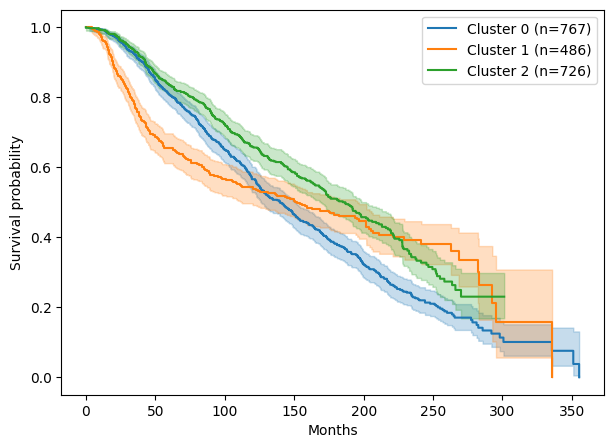

log-rank p-value: 3.2256642530871076e-05


In [28]:
import matplotlib.pyplot as plt
from lifelines import KaplanMeierFitter
from lifelines.statistics import multivariate_logrank_test

kmf = KaplanMeierFitter()
fig, ax = plt.subplots(figsize=(7, 5))
for c, g in data.groupby("cluster"):
    kmf.fit(g["OS_MONTHS"], g["event"], label=f"Cluster {c} (n={len(g)})")
    kmf.plot_survival_function(ax=ax)
plt.xlabel("Months")
plt.ylabel("Survival probability")
plt.show()

res = multivariate_logrank_test(data["OS_MONTHS"], data["cluster"], data["event"])
print("log-rank p-value:", res.p_value)

## 10. What do the clusters mean?
Compare the clusters with known breast cancer subtypes (`CLAUDIN_SUBTYPE`) and with age. These labels were not used to form the clusters.

In [29]:
info = clinical.loc[data.index]
print(pd.crosstab(data["cluster"], info["CLAUDIN_SUBTYPE"]))
print(info.groupby(data["cluster"])["AGE_AT_DIAGNOSIS"].mean())

CLAUDIN_SUBTYPE  Basal  Her2  LumA  LumB  NC  Normal  claudin-low
cluster                                                          
0                    3    70   317   362   2      12            1
1                  196   114     1    16   0      14          145
2                   10    40   382    97   4     122           71
cluster
0    65.747119
1    55.184691
2    60.122713
Name: AGE_AT_DIAGNOSIS, dtype: float64


## 11. Predicting survival
Cox models scored by concordance index (0.5 = chance) with 5-fold cross-validation repeated 3 times, comparing age alone, gene components alone, and both.

In [30]:
import numpy as np
from sklearn.model_selection import KFold
from lifelines import CoxPHFitter
from lifelines.utils import concordance_index

def cv_cindex(df, name, n_splits=5, repeats=3):
    scores = []
    for r in range(repeats):
        for tr, te in KFold(n_splits, shuffle=True, random_state=r).split(df):
            cph = CoxPHFitter(penalizer=0.1)
            cph.fit(df.iloc[tr], duration_col="T", event_col="E")
            risk = cph.predict_partial_hazard(df.iloc[te])
            scores.append(concordance_index(df.iloc[te]["T"], -risk, df.iloc[te]["E"]))
    print(f"{name}: c-index {np.mean(scores):.3f} +/- {np.std(scores):.3f}")

pcs = pd.DataFrame(Z, index=data.index, columns=[f"PC{i+1}" for i in range(10)])
age = info[["AGE_AT_DIAGNOSIS"]]
feat = pcs.join(age)
feat["AGE_AT_DIAGNOSIS"] = (feat["AGE_AT_DIAGNOSIS"] - feat["AGE_AT_DIAGNOSIS"].mean()) / feat["AGE_AT_DIAGNOSIS"].std()
feat["T"] = data["OS_MONTHS"]
feat["E"] = data["event"]
feat = feat.dropna()

pc_cols = [c for c in feat.columns if c.startswith("PC")]
cv_cindex(feat[["AGE_AT_DIAGNOSIS", "T", "E"]], "Age only")
cv_cindex(feat[pc_cols + ["T", "E"]], "10 gene PCs")
cv_cindex(feat, "Age + gene PCs")

Age only: c-index 0.588 +/- 0.022
10 gene PCs: c-index 0.598 +/- 0.020
Age + gene PCs: c-index 0.627 +/- 0.020


## 12. Stronger baseline
Add clinical variables (age, NPI, positive lymph nodes) and test whether gene components still help. Rows with missing values are dropped, so compare these two models only with each other.

In [31]:
clin_cols = ["AGE_AT_DIAGNOSIS", "NPI", "LYMPH_NODES_EXAMINED_POSITIVE"]
f2 = pcs.join(info[clin_cols])
f2[clin_cols] = (f2[clin_cols] - f2[clin_cols].mean()) / f2[clin_cols].std()
f2["T"] = data["OS_MONTHS"]
f2["E"] = data["event"]
f2 = f2.dropna()
print(len(f2), "patients")

cv_cindex(f2[clin_cols + ["T", "E"]], "Clinical only")
cv_cindex(f2, "Clinical + gene PCs")

1903 patients
Clinical only: c-index 0.650 +/- 0.030
Clinical + gene PCs: c-index 0.667 +/- 0.027


## 13. Cluster stability
Re-cluster 30 bootstrap resamples and compare with the original clusters (adjusted Rand index, 1 = identical). Repeated for k = 2 to 5.

In [32]:
from sklearn.metrics import adjusted_rand_score
import numpy as np

rng = np.random.default_rng(0)
orig = data["cluster"].values
scores = []
for b in range(30):
    idx = rng.choice(len(Z), len(Z), replace=True)
    km = KMeans(n_clusters=3, n_init=10, random_state=b).fit(Z[idx])
    scores.append(adjusted_rand_score(orig, km.predict(Z)))

print(f"stability (adjusted Rand index): {np.mean(scores):.2f} +/- {np.std(scores):.2f}")

stability (adjusted Rand index): 0.88 +/- 0.13


## Notes
Results and limitations are in the README. Gene selection and PCA used all patients before cross-validation, so treat the prediction results as exploratory.

In [33]:
for k in [2, 3, 4, 5]:
    orig = KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(Z)
    scores = []
    for b in range(30):
        idx = rng.choice(len(Z), len(Z), replace=True)
        km = KMeans(n_clusters=k, n_init=10, random_state=b).fit(Z[idx])
        scores.append(adjusted_rand_score(orig, km.predict(Z)))
    print(f"k={k}: stability {np.mean(scores):.2f} +/- {np.std(scores):.2f}")

k=2: stability 0.97 +/- 0.02
k=3: stability 0.85 +/- 0.14
k=4: stability 0.91 +/- 0.04
k=5: stability 0.78 +/- 0.19
